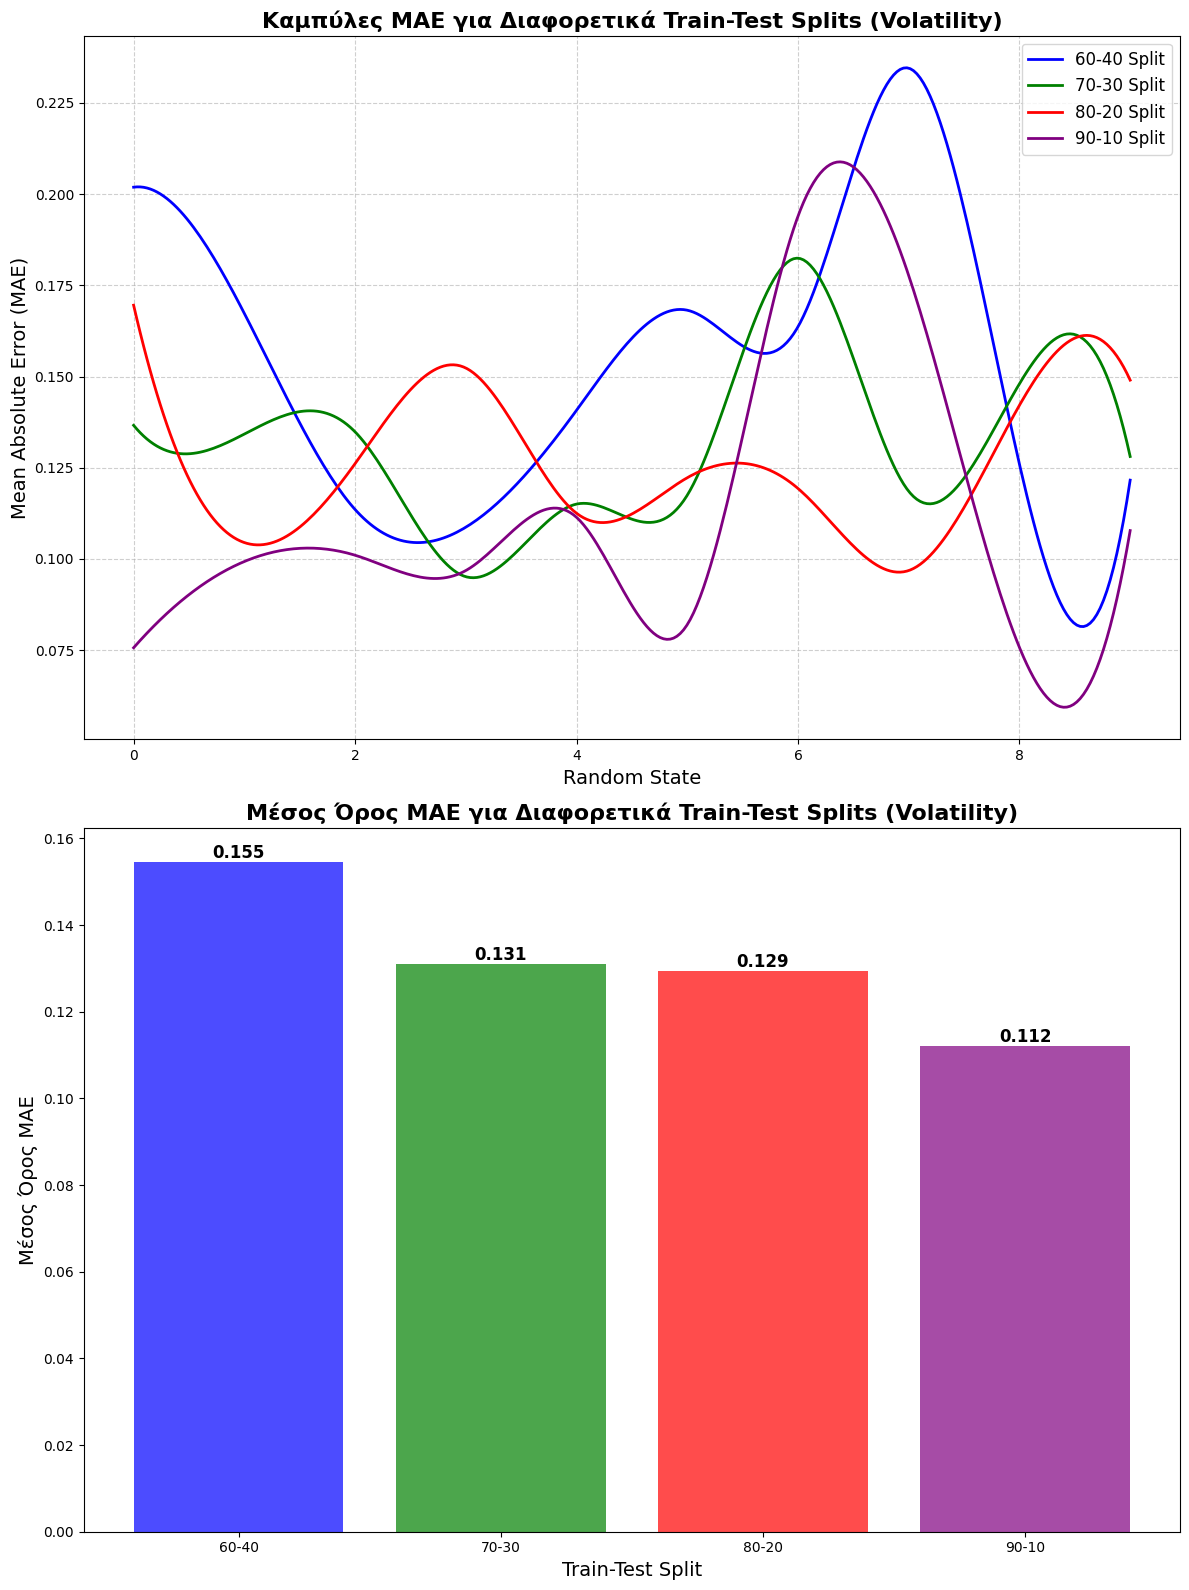

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.interpolate import make_interp_spline

# Δεδομένα για τα splits
random_states = np.array(list(range(10)))

mae_60_40 =np.array([
    0.2018696681681276, 0.16729357573543469, 0.11356308596466674,
    0.10870291024823003, 0.1407389985044333, 0.16816598920787965,
    0.16362564197365867, 0.2344924870178309, 0.12597666028485047,
    0.1216013536187003
])
mae_70_30 = np.array([
    0.13662341597896566, 0.13422522280520813, 0.13483432421167357,
    0.09514244568414303, 0.11504207768035862, 0.11747191960179912,
    0.18241465887027825, 0.11854726290164369, 0.14800741495665615,
    0.1280800178172273
])
mae_80_20 = np.array([
    0.16953796965260776, 0.10449498419685359, 0.12611556766638296,
    0.15232726888636527, 0.11253028478587612, 0.1222627841587994,
    0.11932129288600062, 0.09683127107551712, 0.14212030471195428,
    0.14900247953746867
])
mae_90_10 = np.array([
    0.07567110545699143, 0.09930484753262034, 0.10102951493556699,
    0.09682858525709259, 0.11141553994848416, 0.08200938846852732,
    0.19390966527108283, 0.17767194547973827, 0.07576419094671714,
    0.10778072038641616
])

# Υπολογισμός μέσου όρου για κάθε split
mean_mae = [
    mae_60_40.mean(),
    mae_70_30.mean(),
    mae_80_20.mean(),
    mae_90_10.mean()
]

splits = ["60-40", "70-30", "80-20", "90-10"]

# Δημιουργία λείων καμπυλών με Spline Interpolation
x_smooth = np.linspace(random_states.min(), random_states.max(), 300)

mae_60_40_smooth = make_interp_spline(random_states, mae_60_40)(x_smooth)
mae_70_30_smooth = make_interp_spline(random_states, mae_70_30)(x_smooth)
mae_80_20_smooth = make_interp_spline(random_states, mae_80_20)(x_smooth)
mae_90_10_smooth = make_interp_spline(random_states, mae_90_10)(x_smooth)

# Δημιουργία γραφικής παράστασης
fig, axes = plt.subplots(2, 1, figsize=(12, 16))

# Πρώτο γράφημα: Καμπύλες MAE
axes[0].plot(x_smooth, mae_60_40_smooth, color='blue', label='60-40 Split', linewidth=2)
axes[0].plot(x_smooth, mae_70_30_smooth, color='green', label='70-30 Split', linewidth=2)
axes[0].plot(x_smooth, mae_80_20_smooth, color='red', label='80-20 Split', linewidth=2)
axes[0].plot(x_smooth, mae_90_10_smooth, color='purple', label='90-10 Split', linewidth=2)

axes[0].set_title('Καμπύλες MAE για Διαφορετικά Train-Test Splits (Volatility)', fontsize=16, fontweight='bold')
axes[0].set_xlabel('Random State', fontsize=14)
axes[0].set_ylabel('Mean Absolute Error (MAE)', fontsize=14)
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend(fontsize=12, loc='upper right')

# Δεύτερο γράφημα: Bar Chart Μέσων Όρων MAE
bars = axes[1].bar(splits, mean_mae, color=['blue', 'green', 'red', 'purple'], alpha=0.7)

axes[1].set_title('Μέσος Όρος MAE για Διαφορετικά Train-Test Splits (Volatility)', fontsize=16, fontweight='bold')
axes[1].set_xlabel('Train-Test Split', fontsize=14)
axes[1].set_ylabel('Μέσος Όρος MAE', fontsize=14)

# Προσθήκη τιμών πάνω από τις μπάρες
for bar, value in zip(bars, mean_mae):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{value:.3f}',
        ha='center', va='bottom', fontsize=12, fontweight='bold'
    )

plt.tight_layout()
plt.show()
